# Inversión gravimétrica–magnética M11: matriz física de controles

**Nivel 3 — Análisis de flujo físico**  
**Prerequisitos:** cuadernos conjuntos 1–3, mínimos cuadrados ponderados y regularización cross-gradient; 45 min.

## Objetivos

Inspeccionar ejecuciones reales del solver para controles gravimétricos y magnéticos; reconstruir el resumen de convergencia y acoplamiento por caso; distinguir convergencia, selección retenida, elegibilidad de campo y activación de publicación.

## Preparación

Reads the exact committed M11 precision receipt; no solver is rerun and no files are written. Exact pins: `numpy==2.2.6`, `matplotlib==3.10.8`.

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Datos

El recibo revisado de M11 resume 24 controles ejecutables de gravedad y magnetismo: casos coestructurales, disjuntos, planos/nulos y de campo incorrecto, con geometrías densas, bloqueadas dispersas y desplazadas, y covarianza diagonal o completa. Registra por caso el número de candidatos, acoplamiento seleccionado, finalización del flujo y replay. Todos los modelos y datos de control son sintéticos.

## Método

El objetivo físico es F = f_d,g + f_d,m + beta_g R_g + beta_m R_m + lambda C. Los términos de datos de gravedad y magnetismo se ponderan e informan por separado; cada modalidad tiene su propia línea base optimizada independientemente. C es el término CrossGradient de SimPEG en celdas activas, con la malla y máscaras declaradas. La selección de lambda usa validación y está limitada por la línea base de cada modalidad. Los candidatos no convergidos permanecen en el recibo: no se eliminan ni cuentan como soluciones.

## Estado del arte

La inversión conjunta con acoplamiento cross-gradient es un método estructural establecido. El tutorial oficial de SimPEG muestra otro ejemplo escalar y no valida las unidades, máscaras, covarianza, optimizador ni reglas de aceptación físicas de este repositorio. Esta lección lee el recibo del solver del proyecto, no los resultados del tutorial. Una matriz sintética de 24 casos es un estudio controlado de ingeniería, no evidencia geológica de campo ni beneficio universal del acoplamiento.

## Resultados

El mapa de calor muestra que el acoplamiento seleccionado varía entre controles físicos. Las barras apiladas conservan por caso los candidatos convergidos y no convergidos. El control de tamaño máximo ejercita los límites declarados de grilla, celdas activas, receptores y covarianza. Estas mediciones explican el solver y sus límites de ejecución; no demuestran estructuras únicas ni mejor recuperación retenida.

## Resumen

Se completaron y reprodujeron los 24 flujos locales. En el registro del optimizador, 524 candidatos convergieron y 100 permanecen no convergidos; se conservan estos resultados. El caso de mayor recurso se reprodujo dentro del límite de memoria muestreado. `field_eligible`, la aceptación completa M11 y la activación pública permanecen falsas. La integración del servicio en línea y las puertas del producto completo son independientes.

## Referencias

1. Tutorial de inversión conjunta CrossGradient de SimPEG: https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html.
2. Cockett et al. (2015), SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications, https://doi.org/10.1016/j.cageo.2015.09.015.
3. Métodos y evidencia del repositorio: docs/design/features/joint-survey-inversion/algorithms.md y docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json.

### Experimento 1 — Verificar fuente y los 24 flujos

In [1]:
# Verify receipt identity, schema, case count, execution and replay before plotting.
from pathlib import Path
from importlib.metadata import version
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
root=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json").is_file())
receipt_path=root/"docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json"
raw=receipt_path.read_bytes()
receipt_sha256=hashlib.sha256(raw).hexdigest()
assert receipt_sha256=="2fda6e4748e6f8f6b3c812d9653a3fd06c0748afbe53745ca5b22c8094ad721e", "M11 precision receipt differs from the reviewed immutable result"
r=json.loads(raw)
assert r["schema"]=="caos-geophysics.m11-final-precision-receipt/v1"
records=r["matrix"]["summary"]["records"]
assert len(records)==24 and all(x["workflow_status"]=="completed" and x["replay_validated"] for x in records)
print("Runtime:", {name:version(name) for name in ("numpy","matplotlib")})
print("Pinned receipt SHA-256:", receipt_sha256)
print("Cases / workflows / replay-validated:",len(records),r["matrix"]["complete_cli_workflows"],sum(x["replay_validated"] for x in records))
print("Candidate status totals:",r["matrix"]["candidate_fits"])
print("Field eligible / M11 accepted / public activation:",r["method_scope"]["field_eligible"],r["method_scope"]["full_m11_release_accepted"],r["method_scope"]["public_activation"])

Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
Pinned receipt SHA-256: 2fda6e4748e6f8f6b3c812d9653a3fd06c0748afbe53745ca5b22c8094ad721e
Cases / workflows / replay-validated: 24 24 24
Candidate status totals: {'converged': 524, 'failed': 0, 'nonconverged': 100, 'eligible_positive': 181}
Field eligible / M11 accepted / public activation: False False False


### Experimento 2 — Comparar acoplamiento y resultados del optimizador por caso

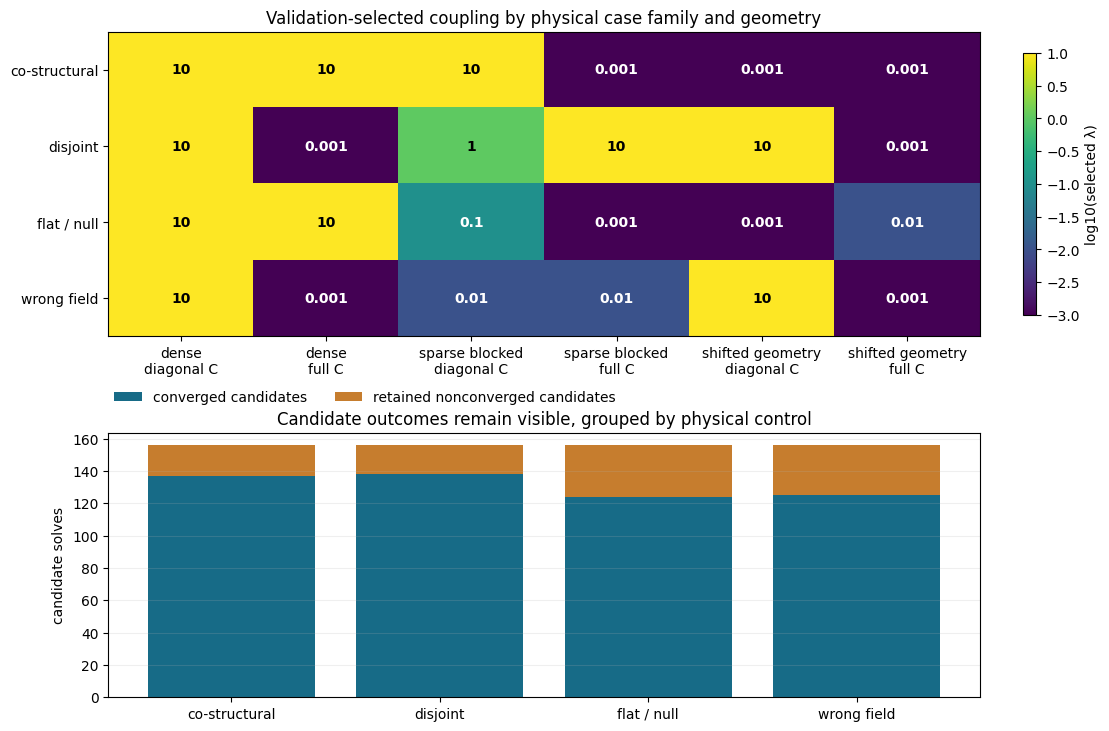

Positive coupling selected: 24 of 24 cases; this is a validation selection outcome, not proof of held-out improvement.


In [2]:
# Reconstruct the physical control matrix from its recorded per-case receipt.
records=r["matrix"]["summary"]["records"]
family_order=["co_structural","disjoint","flat_null","wrong_field"]
regime_order=["dense","sparse_blocked","shifted_geometry"]
columns=[(regime,cov) for regime in regime_order for cov in (False,True)]
coupling=np.full((len(family_order),len(columns)),np.nan)
for item in records:
    row=family_order.index(item["family"])
    col=columns.index((item["regime"],item["covariance"]))
    coupling[row,col]=item["selected_coupling"]
assert np.isfinite(coupling).all()
fig,ax=plt.subplots(2,1,figsize=(11,7.2),constrained_layout=True,gridspec_kw={"height_ratios":[1.15,1]})
image=ax[0].imshow(np.log10(coupling),aspect="auto",cmap="viridis",vmin=-3,vmax=1)
ax[0].set(yticks=np.arange(4),yticklabels=["co-structural","disjoint","flat / null","wrong field"],
          xticks=np.arange(6),xticklabels=[f"{regime.replace('_',' ')}\n{'full' if cov else 'diagonal'} C" for regime,cov in columns],
          title="Validation-selected coupling by physical case family and geometry")
for i in range(coupling.shape[0]):
    for j in range(coupling.shape[1]):
        value=coupling[i,j]
        ax[0].text(j,i,f"{value:g}",ha="center",va="center",color="white" if np.log10(value)<-.2 else "black",fontweight="bold")
fig.colorbar(image,ax=ax[0],label="log10(selected λ)",shrink=.86)
converged=[];nonconverged=[]
for family in family_order:
    subset=[item for item in records if item["family"]==family]
    converged.append(sum(item["candidate_counts"]["converged"] for item in subset))
    nonconverged.append(sum(item["candidate_counts"]["nonconverged"] for item in subset))
positions=np.arange(len(family_order))
ax[1].bar(positions,converged,color="#176b87",label="converged candidates")
ax[1].bar(positions,nonconverged,bottom=converged,color="#c67d2e",label="retained nonconverged candidates")
ax[1].set(xticks=positions,xticklabels=["co-structural","disjoint","flat / null","wrong field"],ylabel="candidate solves",
          title="Candidate outcomes remain visible, grouped by physical control")
ax[1].grid(axis="y",alpha=.2);ax[1].legend(frameon=False,ncol=2,loc="upper left",bbox_to_anchor=(0,1.18),borderaxespad=0)
plt.show()
print("Positive coupling selected:",r["matrix"]["positive_coupling_selected_cases"],"of",r["matrix"]["cases"],"cases; this is a validation selection outcome, not proof of held-out improvement.")

### Experimento 3 — Revisar límites de recursos y precisión

In [3]:
# Keep local resource evidence separate from field eligibility and release acceptance.
resource=r["maximum_count_resource_gate"]
precision=r["exact_face_precision"]
print("Maximum-count physical workflow:")
for key in ("full_cells","active_cells","receivers_per_modality","full_covariance","active_count_plus_one_rejected","workflow_status","workflow_peak_sampled_rss_bytes","replay_validated","field_eligible","public_activation"):
    print(f"  {key}: {resource[key]}")
print("Exact-face controls:",precision["candidate_status_counts"],"accepted scientific predicates:",precision["all_scientific_predicates_pass"])
assert resource["replay_validated"] and resource["field_eligible"] is False and resource["public_activation"] is False
assert r["matrix"]["summary"]["original_precision_failures_retained"] is True
print("Interpretation: resource/replay evidence is scoped to the tested local synthetic controls; nonconvergence is retained, and no field or public activation claim follows.")

Maximum-count physical workflow:
  full_cells: 4096
  active_cells: 1932
  receivers_per_modality: 2048
  full_covariance: True
  active_count_plus_one_rejected: True
  workflow_status: completed
  workflow_peak_sampled_rss_bytes: 494010368
  replay_validated: True
  field_eligible: False
  public_activation: False
Exact-face controls: {'converged': 343, 'nonconverged': 41} accepted scientific predicates: True
Interpretation: resource/replay evidence is scoped to the tested local synthetic controls; nonconvergence is retained, and no field or public activation claim follows.
